In [2]:
%pip install h5py

   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   ----------------------- ---------------- 1.8/3.2 MB 20.2 MB/s eta 0:00:01
   ---------------------------------------- 3.2/3.2 MB 26.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [9]:
%matplotlib notebook

import os, time
import numpy as np
import torch
import torch.nn as nn
from torchsummary import summary
from torch.autograd import Variable
from scipy.io import loadmat

patience = 5
epochs = 400
tra_num = 5000
val_num = 500
syn_num = 200
batch_size = 32
density = [1000, 600]
num_cell = 32
learning_rate = 3e-4
threshold = 1e-4
start_fm = 64
total_num = tra_num + val_num

dataFile = './data/tra&val/data{}.mat'
syn_dataFile = './data/syn/data{}.mat'
model_File = './parameters.pth'

class Reshape(nn.Module):
    def __init__(self, *args):
        super(Reshape, self).__init__()
        self.shape = args
    def forward(self, x):
        return x.view((x.size(0),)+self.shape)


class Dataset(torch.utils.data.Dataset):
    def __init__(self,images,train=True, masks=None):
        self.train = train
        self.images = images
        if self.train:
            self.masks = masks
    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]
        mask = None
        if self.train:
            mask = self.masks[idx]
        return (image, mask)


class double_conv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=1):
        super(double_conv, self).__init__()
        self.conv = nn.Sequential(
                    nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=True),
                    nn.BatchNorm2d(out_channels),
                    nn.ELU(inplace=True),
                    nn.Conv2d(out_channels, out_channels, kernel_size=kernel_size, stride=stride, padding=padding, bias=True),
                    nn.BatchNorm2d(out_channels),
                    nn.ELU(inplace=True))

    def forward(self, x):
        x = self.conv(x)
        return x


class Unet(nn.Module):

    def __init__(self):
        super(Unet, self).__init__()

        self.double_conv1 = double_conv(1, start_fm, 3, 1, 1)
        self.maxpool1 = nn.Sequential(
                        nn.Conv2d(start_fm, start_fm, 2, 2, 0, bias=True),
                        nn.BatchNorm2d(start_fm),
                        nn.ELU(inplace=True))
        self.double_conv2 = double_conv(start_fm, start_fm * 2, 3, 1, 1)
        self.maxpool2 = nn.Sequential(
                    nn.Conv2d(start_fm*2, start_fm*2, 2, 2, 0, bias=True),
                    nn.BatchNorm2d(start_fm*2),
                    nn.ELU(inplace=True))
        self.double_conv3 = double_conv(start_fm * 2, start_fm * 4, 3, 1, 1)
        self.maxpool3 = nn.Sequential(
                    nn.Conv2d(start_fm*4, start_fm*4, 2, 2, 0, bias=True),
                    nn.BatchNorm2d(start_fm*4),
                    nn.ELU(inplace=True))
        self.double_conv4 = double_conv(start_fm * 4, start_fm * 8, 3, 1, 1)
        self.maxpool4 = nn.Sequential(
                nn.Conv2d(start_fm*8, start_fm*8, 2, 2, 0, bias=True),
                nn.BatchNorm2d(start_fm*8),
                nn.ELU(inplace=True))
        self.double_conv5 = double_conv(start_fm * 8, start_fm * 16, 3, 1, 1)

        self.t_conv4 = nn.ConvTranspose2d(start_fm * 16, start_fm * 8, 2, 2)
        self.ex_double_conv4 = double_conv(start_fm * 16, start_fm * 8, 3, 1, 1)
        self.t_conv3 = nn.ConvTranspose2d(start_fm * 8, start_fm * 4, 2, 2)
        self.ex_double_conv3 = double_conv(start_fm * 8, start_fm * 4, 3, 1, 1)
        self.t_conv2 = nn.ConvTranspose2d(start_fm * 4, start_fm * 2, 2, 2)
        self.ex_double_conv2 = double_conv(start_fm * 4, start_fm * 2, 3, 1, 1)
        self.t_conv1 = nn.ConvTranspose2d(start_fm * 2, start_fm, 2, 2)
        self.ex_double_conv1 = double_conv(start_fm * 2, start_fm, 3, 1, 1)
        self.ex_double_conv0 = double_conv(start_fm, 32, 3, 1, 1)
        self.final = nn.Sequential(
                    Reshape(2, 16, num_cell, num_cell),
                    nn.Conv3d(2, 2, kernel_size=1, padding=0, bias=True),
                    nn.BatchNorm3d(2),
                    nn.Sigmoid())


    def forward(self, inputs):

        conv1 = self.double_conv1(inputs)
        maxpool1 = self.maxpool1(conv1)
        maxpool1 = nn.Dropout(0.20)(maxpool1)
        conv2 = self.double_conv2(maxpool1)
        maxpool2 = self.maxpool2(conv2)
        maxpool2 = nn.Dropout(0.20)(maxpool2)
        conv3 = self.double_conv3(maxpool2)
        maxpool3 = self.maxpool3(conv3)
        maxpool3 = nn.Dropout(0.20)(maxpool3)
        conv4 = self.double_conv4(maxpool3)
        maxpool4 = self.maxpool4(conv4)
        maxpool4 = nn.Dropout(0.20)(maxpool4)
        conv5 = self.double_conv5(maxpool4)
        t_conv4 = self.t_conv4(conv5)
        t_conv4 = nn.Dropout(0.20)(t_conv4)
        cat4 = torch.cat([conv4 ,t_conv4], 1)
        ex_conv4 = self.ex_double_conv4(cat4)
        t_conv3 = self.t_conv3(ex_conv4)
        t_conv3 = nn.Dropout(0.20)(t_conv3)
        cat3 = torch.cat([conv3 ,t_conv3], 1)
        ex_conv3 = self.ex_double_conv3(cat3)
        t_conv2 = self.t_conv2(ex_conv3)
        t_conv2 = nn.Dropout(0.20)(t_conv2)
        cat2 = torch.cat([conv2 ,t_conv2], 1)
        ex_conv2 = self.ex_double_conv2(cat2)
        t_conv1 = self.t_conv1(ex_conv2)
        t_conv1 = nn.Dropout(0.20)(t_conv1)
        cat1 = torch.cat([conv1, t_conv1], 1)
        ex_conv1 = self.ex_double_conv1(cat1)
        ex_conv0 = self.ex_double_conv0(ex_conv1)
        result = self.final(ex_conv0)
        return result


class DiceLoss(nn.Module):
    def __init__(self):
        super(DiceLoss, self).__init__()
    def	forward(self, pred, target):
        N = target.size(0)
        smooth = 1
        pred_flat = pred.view(N, -1)
        target_flat = target.view(N, -1)
        intersection = pred_flat * target_flat
        loss = 2 * (intersection.sum(1) + smooth) / ((pred_flat*pred_flat).sum(1) + (target_flat*target_flat).sum(1) + smooth)
        loss = 1 - loss.sum() / N
        return loss


class MulticlassDiceLoss(nn.Module):
    def __init__(self):
        super(MulticlassDiceLoss, self).__init__()
    def forward(self, pred, target, weights=None):
        C = target.shape[1]
        dice = DiceLoss()
        totalLoss = 0
        for i in range(C):
            diceLoss = dice(pred[:,i], target[:,i])
            totalLoss += diceLoss
        return totalLoss/C


def my_loss(pre_y, tru_y, lam=0, beta=0.8):
    MulDice = MulticlassDiceLoss()
    loss = MulDice(pre_y, tru_y)
    return loss


x = []
y = []
for i in range(total_num):
    #data = h5py.File(dataFile.format(i), 'r')
    data =loadmat(dataFile.format(i))
    #m = data['con_m'][:2]
    m = data['con_m'].T
    m[0] = m[0]/density[0]
    m[1] = m[1]/density[1]
    d = data['d']
    d = np.nan_to_num(d)
    x.append(d.reshape(1, num_cell, num_cell))
    y.append(m.reshape(2, 16, num_cell, num_cell))

syn_x = []
syn_y = []
for i in range(syn_num):
    # data = h5py.File(syn_dataFile.format(i), 'r')
    data =loadmat(syn_dataFile.format(i))
    #m = data['con_m'][:2]
    m = data['con_m'].T
    m[0] = m[0]/density[0]
    m[1] = m[1]/density[1]
    d = data['d']
    d = np.nan_to_num(d)
    syn_x.append(d.reshape(1, num_cell, num_cell))
    syn_y.append(m.reshape(2, 16, num_cell, num_cell))

tra_x = x[:tra_num]
tra_y = y[:tra_num]
val_x = x[-val_num:]
val_y = y[-val_num:]

# =====================================================================
# 10. ADD 10% GAUSSIAN NOISE
# =====================================================================
def add_gaussian_noise(data, noise_level=0.1, seed=123):
    rng = np.random.default_rng(seed)
    noisy = data.copy()

    for i in range(len(data)):
        sigma = noise_level * np.std(data[i])
        noise = rng.normal(0.0, sigma, size=data[i].shape).astype(np.float32)
        noisy[i] = data[i] + noise

    return noisy

tra_x = add_gaussian_noise(tra_x, noise_level=0.1, seed=123)
val_x = add_gaussian_noise(val_x, noise_level=0.1, seed=123)
syn_x = add_gaussian_noise(syn_x, noise_level=0.1, seed=123)


print(np.shape(tra_x), np.shape(tra_y))
print(np.shape(val_x), np.shape(val_y))
print(np.shape(syn_x), np.shape(syn_y))


tra_idxs = list(range(len(tra_x)))
val_idxs = list(range(len(val_x)))
syn_idxs = list(range(len(syn_x)))
np.random.shuffle(tra_idxs)
np.random.shuffle(val_idxs)


tra = Dataset(np.array(tra_x).astype(np.float32)[tra_idxs], train=True, masks=np.array(tra_y).astype(np.float32)[tra_idxs])
val = Dataset(np.array(val_x).astype(np.float32)[val_idxs], train=True, masks=np.array(val_y).astype(np.float32)[val_idxs])
syn = Dataset(np.array(syn_x).astype(np.float32)[syn_idxs], train=True, masks=np.array(syn_y).astype(np.float32)[syn_idxs])
tra_loader = torch.utils.data.DataLoader(dataset=tra, batch_size=batch_size, shuffle=False, pin_memory=False)
val_loader = torch.utils.data.DataLoader(dataset=val, batch_size=batch_size, shuffle=False, pin_memory=False)
syn_loader = torch.utils.data.DataLoader(dataset=syn, batch_size=batch_size, shuffle=False, pin_memory=False)


model = Unet()
model.cuda()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
summary(model, input_size=(1, 32, 32))


mean_tra_losses = []
mean_val_losses = []
mean_syn_losses = []
val_data = []
syn_data = []

start = time.time()
epoch = 0
while epoch <= epochs:
    tra_losses = []
    val_losses = []
    syn_losses = []
    model.train()
    for images, masks in tra_loader:
        images = Variable(images.cuda())
        masks = Variable(masks.cuda())
        optimizer.zero_grad()
        outputs = model(images)
        loss = my_loss(outputs, masks)
        loss.backward()
        optimizer.step()
        tra_losses.append(loss.data)

    model.eval()
    for images, masks in val_loader:
        images = Variable(images.cuda())
        masks = Variable(masks.cuda())
        with torch.no_grad():
            outputs = model(images)
            val_loss = my_loss(outputs, masks)
            val_losses.append(val_loss.data)
            if (epoch > patience and abs(mean_val_losses[-patience] - mean_val_losses[-1]) < threshold) or epoch == epochs:
                val_data.extend([[outputs, masks, images]])

    for images, masks in syn_loader:
        images = Variable(images.cuda())
        masks = Variable(masks.cuda())
        with torch.no_grad():
            outputs = model(images)
            syn_loss = my_loss(outputs, masks)
            syn_losses.append(syn_loss.data)
            if (epoch > patience and abs(mean_val_losses[-patience] - mean_val_losses[-1]) < threshold) or epoch == epochs:
                syn_data.extend([[outputs, masks, images]])

    if epoch > patience and abs(mean_val_losses[-patience] - mean_val_losses[-1]) < threshold or epoch == epochs:
        torch.save(model.state_dict(), model_File)
        print("Early stopping")
        break

    epoch += 1
    mean_tra_losses.append(torch.mean(torch.stack(tra_losses)))
    mean_val_losses.append(torch.mean(torch.stack(val_losses)))
    mean_syn_losses.append(torch.mean(torch.stack(syn_losses)))
    print('Epoch: %d. Tra Loss: %0.4f. Val Loss: %0.4f. Syn Loss: %0.4f'%(epoch, torch.mean(torch.stack(tra_losses)), torch.mean(torch.stack(val_losses)), torch.mean(torch.stack(syn_losses))))

end = time.time()
run_time = end - start


syn_data = []
model.load_state_dict(torch.load(model_File))
model.eval()
for images, masks in syn_loader:
    with torch.no_grad():
        images = Variable(images.cuda())
        masks = Variable(masks.cuda())
        outputs = model(images)
        syn_data.extend([[outputs, masks, images]])


#val_data = np.array(val_data)
val_truth = []
val_predict = []
val_truth_d = []
for p, q  in enumerate(val_data):
    for i, j  in enumerate(q[1]):
        val_truth.append(j.reshape(2, 16384).cpu().numpy())
    for i, j  in enumerate(q[0]):
        val_predict.append(j.reshape(2, 16384).cpu().numpy())
    for i, j  in enumerate(q[2]):
        val_truth_d.append(j.reshape(1, 1024)[0].cpu().numpy())

#syn_data = np.array(syn_data)
syn_truth = []
syn_predict = []
syn_truth_d = []
for p, q  in enumerate(syn_data):
    for i, j  in enumerate(q[1]):
        syn_truth.append(j.reshape(2, 16384).cpu().numpy())
    for i, j  in enumerate(q[0]):
        syn_predict.append(j.reshape(2, 16384).cpu().numpy())
    for i, j  in enumerate(q[2]):
        syn_truth_d.append(j.reshape(1, 1024)[0].cpu().numpy())





# =====================================================================
# SAVE ALL INVERSION RESULTS FOR FUTURE USE
# =====================================================================

results_file = "./CNN_inversion_results.npz"

np.savez_compressed(
    results_file,

    # ---------------- Final validation results ----------------
    val_truth=np.asarray(val_truth),
    val_predict=np.asarray(val_predict),
    val_truth_d=np.asarray(val_truth_d),

    # ---------------- Final synthetic results -----------------
    syn_truth=np.asarray(syn_truth),
    syn_predict=np.asarray(syn_predict),
    syn_truth_d=np.asarray(syn_truth_d),

    # ---------------- Convergence histories -------------------
    mean_tra_losses=np.asarray([
        x.detach().cpu().item() for x in mean_tra_losses
    ]),
    mean_val_losses=np.asarray([
        x.detach().cpu().item() for x in mean_val_losses
    ]),
    mean_syn_losses=np.asarray([
        x.detach().cpu().item() for x in mean_syn_losses
    ]),

    # ---------------- Training information --------------------
    last_epoch=int(epoch),
    training_time=float(run_time),

    # ---------------- Model parameters -----------------------
    density=np.asarray(density),
    num_cell=int(num_cell),
    num_depth=16,
    tra_num=int(tra_num),
    val_num=int(val_num),
    syn_num=int(syn_num),
    batch_size=int(batch_size),
    learning_rate=float(learning_rate),
    start_fm=int(start_fm)
)
print("\n==============================================")
print("ALL INVERSION RESULTS SAVED SUCCESSFULLY")
print("==============================================")
print("Results file :", results_file)
print("Validation   :", np.asarray(val_predict).shape)
print("Synthetic    :", np.asarray(syn_predict).shape)
print("Epochs       :", len(mean_val_losses))
print("Training time:", run_time, "seconds")
print("Model file   :", model_File)
print("==============================================")

(5000, 1, 32, 32) (5000, 2, 16, 32, 32)
(500, 1, 32, 32) (500, 2, 16, 32, 32)
(200, 1, 32, 32) (200, 2, 16, 32, 32)
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]             640
       BatchNorm2d-2           [-1, 64, 32, 32]             128
               ELU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,928
       BatchNorm2d-5           [-1, 64, 32, 32]             128
               ELU-6           [-1, 64, 32, 32]               0
       double_conv-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 16, 16]          16,448
       BatchNorm2d-9           [-1, 64, 16, 16]             128
              ELU-10           [-1, 64, 16, 16]               0
           Conv2d-11          [-1, 128, 16, 16]          73,856
      BatchNorm2d-12          [-1, 128, 16, 16]    


SAVED CNN INVERSION RESULTS LOADED
Validation truth      : (500, 2, 16384)
Validation prediction : (500, 2, 16384)
Synthetic truth       : (200, 2, 16384)
Synthetic prediction  : (200, 2, 16384)
Synthetic data        : (200, 1024)
Number of epochs      : 189
Training time         : 2115.7562935352325 seconds
Txz matrix shape: (1024, 16384)
True model shape : (2, 16, 32, 32)
Pred model shape : (2, 16, 32, 32)
obs_txz =
 [[ 3.596267    3.5803397   1.3653017  ... -1.1544095  -0.87066376
  -1.6762611 ]
 [ 4.262159    1.9530089   3.9419494  ...  0.24764235 -2.269789
  -0.17648599]
 [ 5.604413    7.7041216  -0.2669708  ... -1.219463   -1.3355272
  -1.6212677 ]
 ...
 [ 0.29291233  0.8430667  -0.12009446 ...  1.2092078   0.7771082
   2.5028012 ]
 [-0.49357224  4.9735355  -1.2390974  ... -1.6494598  -0.97033745
  -2.8468106 ]
 [ 0.5622544   1.8406252  -2.7064254  ...  2.3426805  -2.7198226
  -3.2781901 ]]

pre_txz =
 [[ 4.110739    3.70407677  3.4514163  ... -2.27547739 -2.50356458
  -3.576791

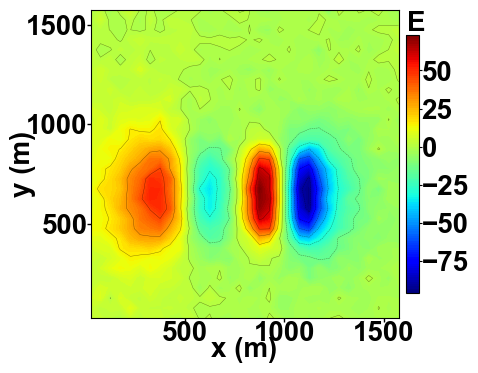

Saved: Fig01_Observed_txz.png


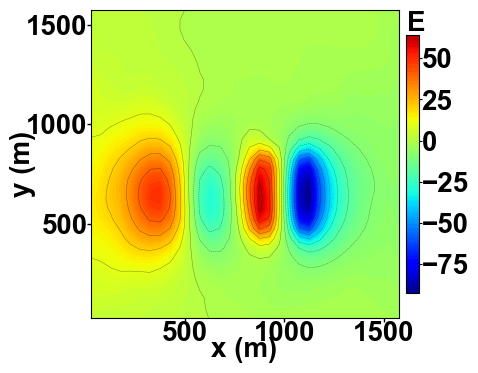

Saved: Fig02_Predicted_txz.png


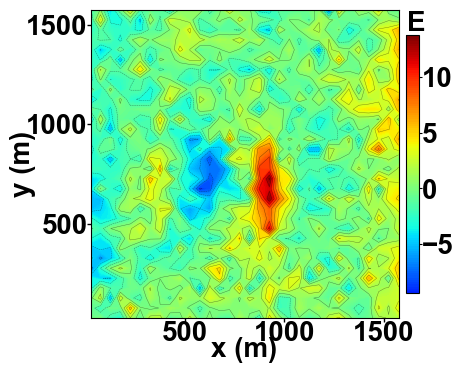

Saved: Fig03_Residual_txz.png


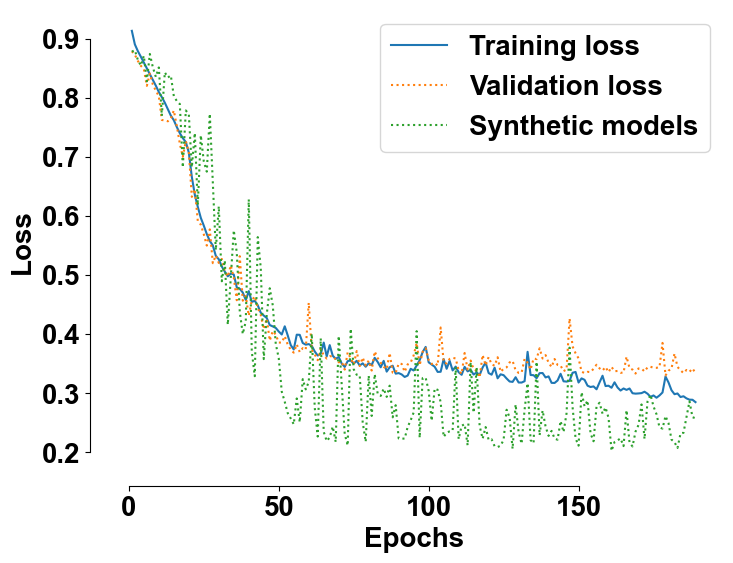

Saved: CNN_Fig04_Convergence.png
Convergence data saved to: C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\two_prisms_cnn\Convergence_Curve_Combined_all_Components\txz_Conver_Curve_Data.xlsx
True density range     : 0.0 1000.0 kg/m³
Predicted density range: 0.004565669314615661 999.991774559021 kg/m³


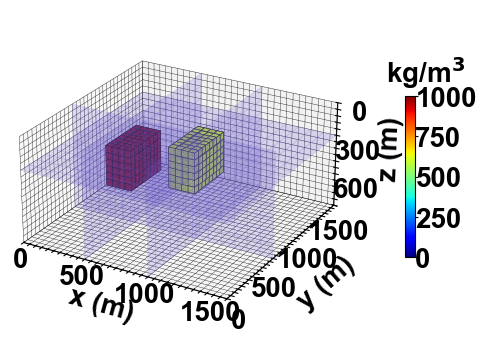

Saved: Fig05_True_3D_Density_Model.png


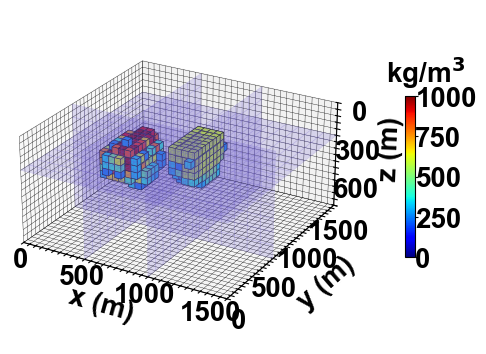

Saved: Fig06_Predicted_3D_Density_Model.png


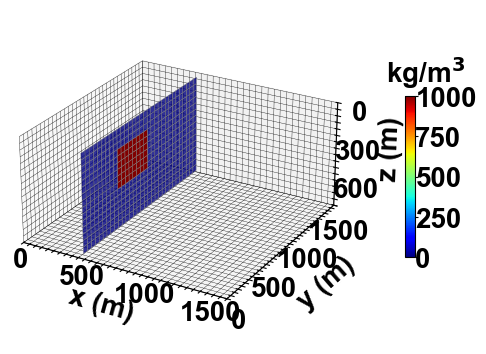

Saved: Fig07_True_YZ_x500.png


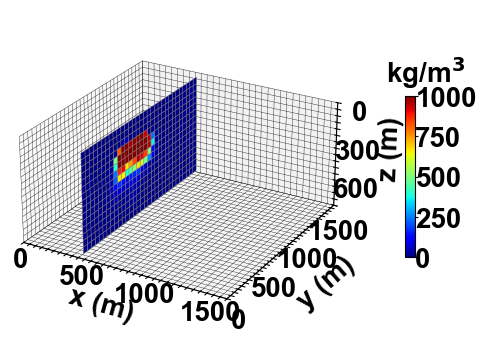

Saved: Fig08_Predicted_YZ_x500.png


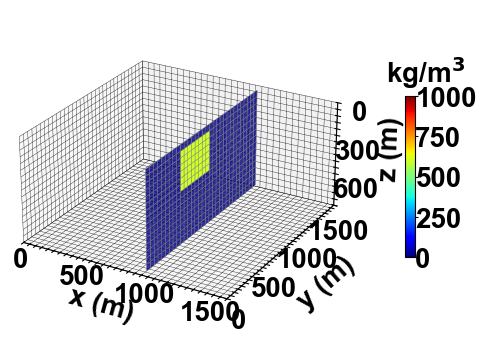

Saved: Fig09_True_YZ_x1000.png


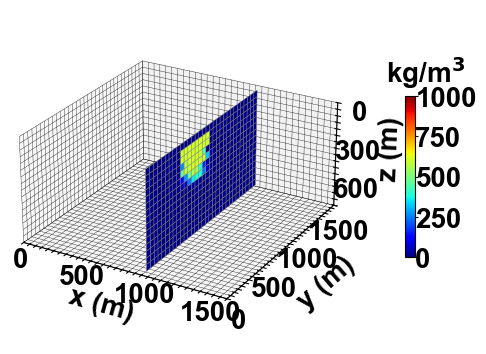

Saved: Fig10_Predicted_YZ_x1000.png


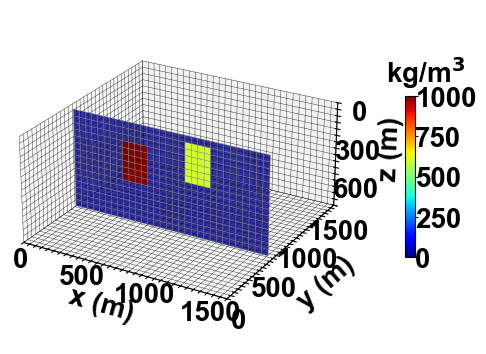

Saved: Fig11_True_XZ_y650.png


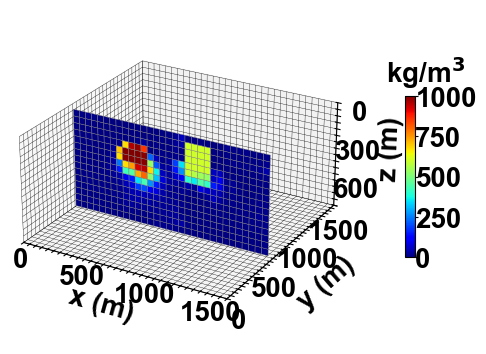

Saved: Fig12_Predicted_XZ_y650.png


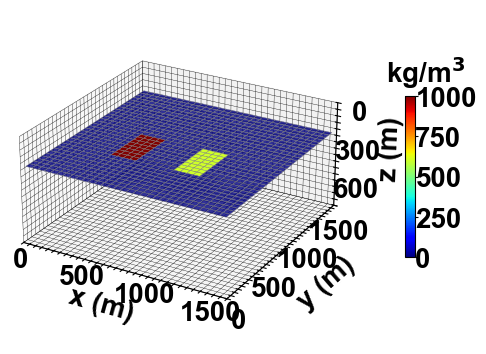

Saved: Fig13_True_XY_z250.png


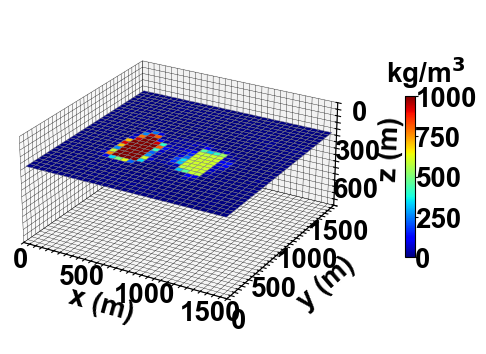

Saved: Fig14_Predicted_XY_z250.png

ALL 14 TWO-PRISM FIGURES SAVED SUCCESSFULLY
PNG resolution: 600 DPI


In [4]:
%matplotlib inline
import torch
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image, ImageChops
import seaborn as sns
from scipy.io import loadmat
from matplotlib.ticker import ScalarFormatter, MaxNLocator

# =====================================================================
# LOAD SAVED CNN INVERSION RESULTS
# =====================================================================
results_file = "./CNN_inversion_results.npz"
results = np.load(results_file)

# Final validation inversion
val_truth   = results["val_truth"]
val_predict = results["val_predict"]
val_truth_d = results["val_truth_d"]

# Final synthetic inversion
syn_truth   = results["syn_truth"]
syn_predict = results["syn_predict"]
syn_truth_d = results["syn_truth_d"]

# Convergence histories
mean_tra_losses = results["mean_tra_losses"]
mean_val_losses = results["mean_val_losses"]
mean_syn_losses = results["mean_syn_losses"]

# Training information
last_epoch  = int(results["last_epoch"])
run_time    = float(results["training_time"])

# Model parameters
density     = results["density"]
num_cell    = int(results["num_cell"])
num_depth   = int(results["num_depth"])
#noise_level = float(results["noise_level"])

print("\n==============================================")
print("SAVED CNN INVERSION RESULTS LOADED")
print("==============================================")
print("Validation truth      :", val_truth.shape)
print("Validation prediction :", val_predict.shape)
print("Synthetic truth       :", syn_truth.shape)
print("Synthetic prediction  :", syn_predict.shape)
print("Synthetic data        :", syn_truth_d.shape)
print("Number of epochs      :", last_epoch)
print("Training time         :", run_time, "seconds")
print("==============================================")



# =====================================================================
# CELL 2 — TWO-PRISM CNN PLOT AND SAVE 14 FIGURES
# Pure and Applied Geophysics — Publication Quality
# =====================================================================

# -------------------- Global publication style --------------------
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Arial","font.size":20,
    "axes.labelsize":20,"axes.titlesize":20,"xtick.labelsize":20,"ytick.labelsize":20,
    "legend.fontsize":20,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})
# -------------------- Axis / colorbar style --------------------
def _style(ax,xl="",yl=""):
    ax.set_facecolor(AX)
    ax.tick_params(axis="both",colors=TC,
                   direction="out",width=1.0,length=3.0,pad=-1.0)
    ax.set_xlabel(xl,color=TC,labelpad=-7.0)
    ax.set_ylabel(yl,color=TC,labelpad=-7.0)
    for sp in ax.spines.values():
        sp.set_edgecolor(TC); sp.set_linewidth(.8)

def _publication_colorbar(cf,ax,fig,title,scientific=False):
    cb=fig.colorbar(cf,ax=ax,shrink=0.84,pad=0.02,aspect=21)
    cb.ax.set_title(title,color=TC,y=0.98,x=0.8)
    cb.locator=MaxNLocator(nbins=7,steps=[1,2,2.5,5,10])  # Clean tick spacing
    cb.update_ticks()
    cb.ax.tick_params(colors=TC,direction="out",
                      width=.8,length=2,pad=0.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    fmt=ScalarFormatter(useMathText=False)
    fmt.set_scientific(scientific); fmt.set_useOffset(False)
    cb.formatter=fmt; cb.update_ticks()
    return cb

def save_fig(fig,filename,tight=True):
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
        
# -------------------- Grid / observation data --------------------
nx=ny=32; nz=16
dx=dy=dz=50.
density=np.array([1000.,600.])

xe=np.linspace(0,1600,nx+1)
ye=np.linspace(0,1600,ny+1)
ze=np.linspace(0,800,nz+1)
xc=.5*(xe[:-1]+xe[1:])
yc=.5*(ye[:-1]+ye[1:])
zc=.5*(ze[:-1]+ze[1:])

sp=50.
x1d=np.arange(sp/2,1600,sp)
y1d=np.arange(sp/2,1600,sp)
Xo,Yo=np.meshgrid(x1d,y1d)
obs_x,obs_y=Xo.ravel(),Yo.ravel()
N_obs=len(obs_x)

# ── 3. Load Txz kernel ───────────────────────────────────────────
Txz=np.nan_to_num(loadmat(
    r'C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\Sigle prism cnn\txz_inv\Txz_matrix.mat'
)['Txz'])
print("Txz matrix shape:",Txz.shape)

# =====================================================================
# 2. SELECT CNN SYNTHETIC MODEL
# =====================================================================
index=10
m1=syn_truth[index]
m2=syn_predict[index]
obs_txz=np.asarray(syn_truth_d[index]).reshape(ny,nx)

# Two-prism normalized CNN models: (component,z,y,x)
tru_model=m1.reshape(2,nz,ny,nx)
pre_model=m2.reshape(2,nz,ny,nx)

print("True model shape :",tru_model.shape)
print("Pred model shape :",pre_model.shape)

# =====================================================================
# 3. OBSERVED / PREDICTED txz
# =====================================================================
Zobs=obs_txz
Zpred=np.zeros_like(Zobs,dtype=float)

# Sum txz response from both predicted prisms
for i in range(2):
    Zpred+=(Txz@(density[i]*pre_model[i].reshape(-1,1))).reshape(ny,nx)
pre_txz = Zpred
Zres=Zobs-Zpred
X=obs_x.reshape(ny,nx); Y=obs_y.reshape(ny,nx)
vmin=min(Zobs.min(),Zpred.min())
vmax=max(Zobs.max(),Zpred.max())
rmax=np.max(np.abs(Zres))

# ============================================================
# Tensor and residual statistics
# ============================================================
# Observed and predicted txz data
print("obs_txz =\n", obs_txz)
print("\npre_txz =\n", pre_txz)
# Residual Tensor : observed - predicted
print("\nZres =\n", Zres)

# Maximum, Minimum & Mean values of observed txz data
print("\nobs_txz maximum =", np.max(obs_txz))
print("obs_txz minimum =", np.min(obs_txz))
print("obs_txz mean =", np.mean(obs_txz))

# Maximum, Minimum & Mean values of predicted txz data 
print("\npre_txz maximum =", np.max(pre_txz))
print("pre_txz minimum =", np.min(pre_txz))
print("pre_txz mean =", np.mean(pre_txz))

# Residual statistics
print("\nZres maximum =", np.max(Zres))
print("Zres minimum =", np.min(Zres))
print("Zres mean =", np.mean(Zres))

# RMS residual
rms = np.sqrt(np.mean(Zres**2))
print("\nRMS between observed and predicted =", rms)

# =====================================================================
# 4. 2-D txz PLOTS — FIGURES 1–3
# =====================================================================
def plot_txz(data,filename,label,lo,hi):
    fig,ax=plt.subplots(figsize=(5,4)); fig.patch.set_facecolor(BG)
    cf=ax.contourf(X,Y,data,levels=150,cmap="jet",vmin=lo,vmax=hi)
    ax.contour(X,Y,data,levels=15,colors="k",linewidths=.3,alpha=.5)
    _style(ax,"x (m)","y (m)"); ax.set_aspect("equal")
    _publication_colorbar(cf,ax,fig,"E")
    save_fig(fig,filename)

plot_txz(Zobs,"Fig01_Observed_txz.png","txz (E)",vmin,vmax)
plot_txz(Zpred,"Fig02_Predicted_txz.png","txz (E)",vmin,vmax)
plot_txz(Zres,"Fig03_Residual_txz.png","txz residual (E)",-rmax,rmax)

# ── 11. FIGURE 4 — CONVERGENCE ────────────────────────────────────────
mean_tra_losses = [x.cpu().item() if torch.is_tensor(x) else x for x in mean_tra_losses]
mean_val_losses = [x.cpu().item() if torch.is_tensor(x) else x for x in mean_val_losses]
mean_syn_losses = [x.cpu().item() if torch.is_tensor(x) else x for x in mean_syn_losses]

epochs=np.arange(1,len(mean_tra_losses)+1)
fig,ax=plt.subplots(figsize=(8,6))
ax.plot(epochs,mean_tra_losses,label="Training loss")
ax.plot(epochs,mean_val_losses,":",label="Validation loss")
ax.plot(epochs,mean_syn_losses,":",label="Synthetic models")
sns.despine(offset=10,trim=True); ax.set_xlabel("Epochs"); ax.set_ylabel("Loss"); ax.legend(loc="best")
save_fig(fig, "CNN_Fig04_Convergence.png")

# ── 12. SAVE CONVERGENCE DATA ─────────────────────────────────────────
df=pd.DataFrame({"Epoch":epochs,"Training Loss":mean_tra_losses,
                 "Validation Loss":mean_val_losses,"Synthetic Loss":mean_syn_losses})
excel_file=r"C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\two_prisms_cnn\Convergence_Curve_Combined_all_Components\txz_Conver_Curve_Data.xlsx"
df.to_excel(excel_file,index=False); print("Convergence data saved to:",excel_file)
# =====================================================================
# 6. CONVERT TWO CNN COMPONENTS TO PHYSICAL DENSITY
# =====================================================================
# Each CNN component is normalized; convert using its own density.
mt3=np.max(
    np.array([tru_model[i]*density[i] for i in range(2)]),axis=0)
mp3=np.max(
    np.array([pre_model[i]*density[i] for i in range(2)]),axis=0)

print("True density range     :",mt3.min(),mt3.max(),"kg/m³")
print("Predicted density range:",mp3.min(),mp3.max(),"kg/m³")
# =====================================================================
# 7. TRUE PRISM BOUNDARIES
# =====================================================================
p1_xlo,p1_xhi,p1_ylo,p1_yhi,p1_zlo,p1_zhi=400,600,450,850,150,450
p2_xlo,p2_xhi,p2_ylo,p2_yhi,p2_zlo,p2_zhi=900,1100,450,850,50,350
# =====================================================================
# 8. COMMON 3-D SETTINGS
# =====================================================================
cmap_3d=plt.cm.jet
norm=plt.Normalize(vmin=0,vmax=1000)
X3,Y3,Z3=np.meshgrid(xe,ye,ze,indexing="ij")

def setup_3d(ax):
    ax.set_xlim(0,1600); ax.set_ylim(0,1600); ax.set_zlim(800,0)

    xg=np.arange(0,1601,50)
    yg=np.arange(0,1601,50)
    zg=np.arange(0,801,50)

    ax.set_xticks(xg); ax.set_yticks(yg); ax.set_zticks(zg)
    ax.set_xticklabels([str(v) if v%500==0 else "" for v in xg])
    ax.set_yticklabels([str(v) if v%500==0 else "" for v in yg])
    ax.set_zticklabels([str(v) if v%300==0 else "" for v in zg])

    ax.set_xlabel("x (m)",color=TC,labelpad=0.0); ax.set_ylabel("y (m)",color=TC,labelpad=5)
    ax.set_zlabel("z (m)",color=TC,labelpad=2.0)
    
    ax.tick_params(axis="x",colors=TC,direction="out",
                   width=.7,length=3,pad=-5.0)
    ax.tick_params(axis="y",colors=TC,direction="out",
                   width=.7,length=3,pad=-1.0)
    ax.tick_params(axis="z",colors=TC,direction="out",
                   width=.7,length=3,pad=1.0) 
    ax.grid(True)
    for a in [ax.xaxis,ax.yaxis,ax.zaxis]:
        a._axinfo["grid"].update(
            color="black",linewidth=.25,linestyle="-")

    ax.set_facecolor(AX)
    ax.set_box_aspect((1600,1600,800))
    ax.view_init(elev=25,azim=-60)
# =====================================================================
# 9. DENSITY BOUNDARY PLANES
# =====================================================================
def add_density_boundaries(ax,xe,ye,ze,alpha=.2):

    Y,Z=np.meshgrid(ye,ze)

    # Prism 1 centre x = 500 m
    X=np.full_like(Y,500.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,
                    rstride=2,cstride=2,shade=False)

    # Prism 2 centre x = 1000 m
    X=np.full_like(Y,1000.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,
                    rstride=2,cstride=2,shade=False)

    # Common y = 650 m plane
    X,Z=np.meshgrid(xe,ze)
    Y=np.full_like(X,650.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,
                    rstride=2,cstride=2,shade=False)

    # Common z = 250 m plane
    X,Y=np.meshgrid(xe,ye)
    Z=np.full_like(X,250.,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,
                    edgecolor="slateblue",linewidth=.35,
                    rstride=2,cstride=2,shade=False)
# =====================================================================
# 10. 3-D DENSITY COLORBAR
# =====================================================================
def density_3d_colorbar(fig,ax):
    sm=mpl.cm.ScalarMappable(cmap=cmap_3d,norm=norm)
    sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=0.42,pad=0.13,aspect=16)
    cb.ax.set_title(r"kg/m$^3$",color=TC,y=1.03,x=2.0)
    cb.set_ticks(np.arange(0,1001,250))
    cb.ax.tick_params(colors=TC,direction="out",
                      width=.8,length=2,pad=-2.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
# =====================================================================
# 11. 3-D DENSITY MODEL
# =====================================================================
def plot_3d_model(arr,filename,threshold):
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")

    # Threshold is in kg/m³
    filled=arr>threshold
    fc=np.zeros((*arr.shape,4))
    fc[filled]=cmap_3d(norm(arr[filled]))

    ax.voxels(
        X3,Y3,Z3,filled.transpose(2,1,0),
        facecolors=fc.transpose(2,1,0,3),
        edgecolor="black",linewidth=.4,alpha=1,shade=False)

    add_density_boundaries(ax,xe,ye,ze,.2)
    density_3d_colorbar(fig,ax)
    setup_3d(ax)
    save_fig(fig,filename)
# =====================================================================
# 12. FIGURES 5–6 — TRUE / PREDICTED 3-D MODELS
# =====================================================================
plot_3d_model(mt3,"Fig05_True_3D_Density_Model.png",50)
plot_3d_model(mp3,"Fig06_Predicted_3D_Density_Model.png",250)
# =====================================================================
# 13. DENSITY SLICES
# =====================================================================
def plot_density_slice(model3d,x_slice=None,y_slice=None,
                       z_slice=None,filename=""):

    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG)
    ax=fig.add_subplot(111,projection="3d")

    if x_slice is not None:
        ix=np.argmin(np.abs(xc-x_slice))
        Y,Z=np.meshgrid(yc,zc)
        X=np.full_like(Y,xc[ix])
        rho=model3d[:,:,ix]

    elif y_slice is not None:
        iy=np.argmin(np.abs(yc-y_slice))
        X,Z=np.meshgrid(xc,zc)
        Y=np.full_like(X,yc[iy])
        rho=model3d[:,iy,:]

    elif z_slice is not None:
        iz=np.argmin(np.abs(zc-z_slice))
        X,Y=np.meshgrid(xc,yc)
        Z=np.full_like(X,zc[iz])
        rho=model3d[iz,:,:]

    else:
        plt.close(fig); return

    fc=cmap_3d(norm(rho))
    fc[...,3]=np.where(np.abs(rho)>1e-12,1.,.8)

    ax.plot_surface(
        X,Y,Z,facecolors=fc,rstride=1,cstride=1,
        linewidth=.3,edgecolor="gray",
        shade=False,antialiased=True)
    setup_3d(ax)
    density_3d_colorbar(fig,ax)
    save_fig(fig,filename)
# =====================================================================
# 14. FIGURES 7–14 — DENSITY SLICES
# =====================================================================
plot_density_slice(mt3,x_slice=500,
                    filename="Fig07_True_YZ_x500.png")
plot_density_slice(mp3,x_slice=500,
                    filename="Fig08_Predicted_YZ_x500.png")

plot_density_slice(mt3,x_slice=1000,
                    filename="Fig09_True_YZ_x1000.png")
plot_density_slice(mp3,x_slice=1000,
                    filename="Fig10_Predicted_YZ_x1000.png")

plot_density_slice(mt3,y_slice=650,
                    filename="Fig11_True_XZ_y650.png")
plot_density_slice(mp3,y_slice=650,
                    filename="Fig12_Predicted_XZ_y650.png")

plot_density_slice(mt3,z_slice=250,
                    filename="Fig13_True_XY_z250.png")
plot_density_slice(mp3,z_slice=250,
                    filename="Fig14_Predicted_XY_z250.png")
# =====================================================================
# COMPLETE
# =====================================================================
print("\n==============================================")
print("ALL 14 TWO-PRISM FIGURES SAVED SUCCESSFULLY")
print("PNG resolution: 600 DPI")
print("==============================================")

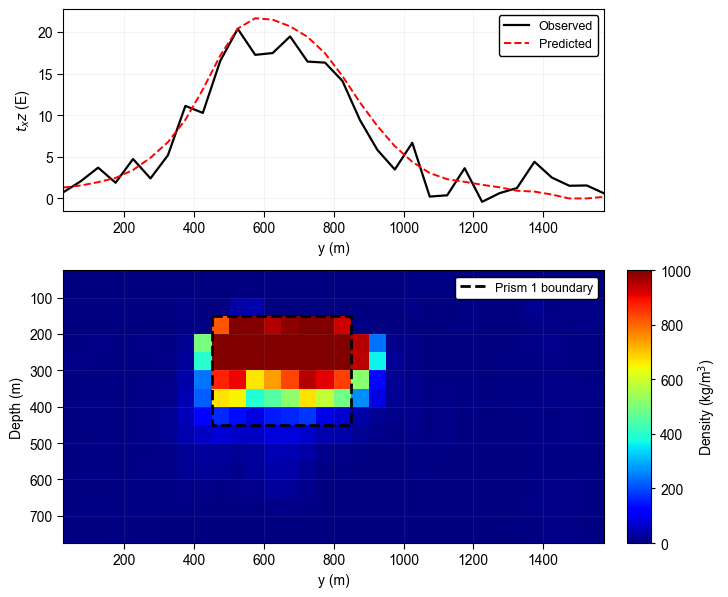

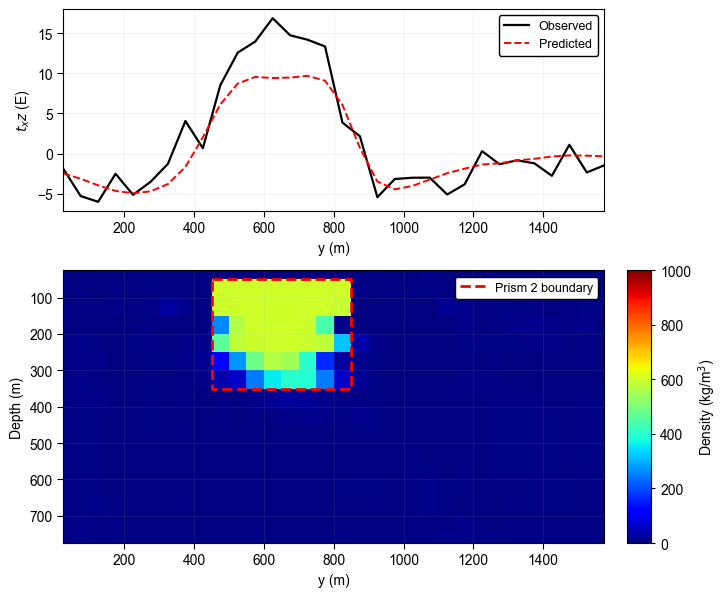

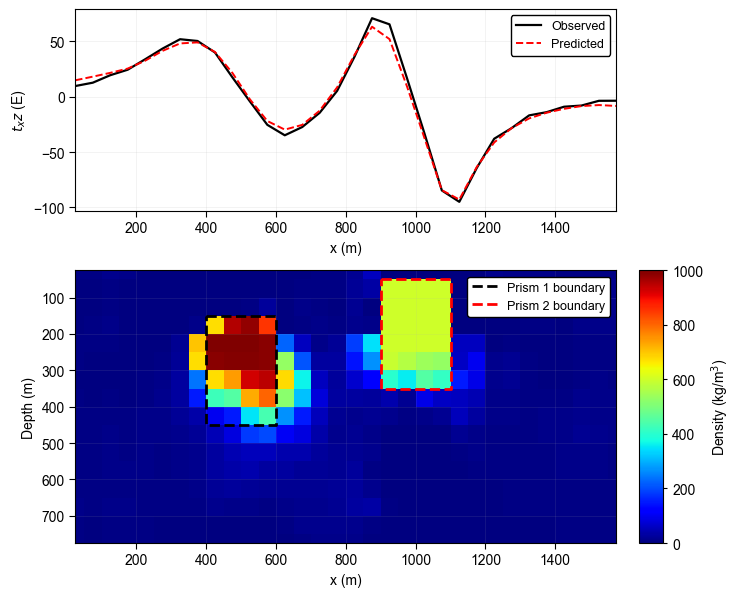

In [3]:
# =====================================================================
# 14–16. TWO-PRISM txz PROFILES + DENSITY SECTIONS
# =====================================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl

# =====================================================================
# TRUE TWO-PRISM BOUNDS
# =====================================================================
p1_xlo,p1_xhi,p1_ylo,p1_yhi,p1_zlo,p1_zhi=400.,600.,450.,850.,150.,450.
p2_xlo,p2_xhi,p2_ylo,p2_yhi,p2_zlo,p2_zhi=900.,1100.,450.,850.,50.,350.

# =====================================================================
# PROFILE + DENSITY-SECTION FUNCTION
# =====================================================================
def plot_profile_density_section(direction,coordinate,filename):

    direction=direction.upper()
    xc,yc,zc=[(a[:-1]+a[1:])/2 for a in (xe,ye,ze)]

    if direction=="EW":
        i=np.argmin(np.abs(Y[:,0]-coordinate))
        profile,obs,pred=X[i],Zobs[i],Zpred[i]
        pd.DataFrame({"x (m)":profile,"Observed txz (E)":obs,
                      "Predicted txz (E)":pred}).to_excel(
                      f"XZ_txz_Profile_y{int(coordinate)}.xlsx",index=False)
        j=np.argmin(np.abs(yc-coordinate))
        section=mp3[:,j,:]
        Xsec,Zsec=np.meshgrid(xc,zc)
        xlabel="x (m)"
        b1=[p1_xlo,p1_xhi,p1_xhi,p1_xlo,p1_xlo]
        b2=[p2_xlo,p2_xhi,p2_xhi,p2_xlo,p2_xlo]
        show1=p1_ylo<=coordinate<=p1_yhi
        show2=p2_ylo<=coordinate<=p2_yhi

    elif direction=="NS":
        i=np.argmin(np.abs(X[0]-coordinate))
        profile,obs,pred=Y[:,i],Zobs[:,i],Zpred[:,i]
        pd.DataFrame({"y (m)":profile,"Observed txz (E)":obs,
                      "Predicted txz (E)":pred}).to_excel(
                      f"YZ_txz_Profile_x{int(coordinate)}.xlsx",index=False)
        j=np.argmin(np.abs(xc-coordinate))
        section=mp3[:,:,j]
        Xsec,Zsec=np.meshgrid(yc,zc)
        xlabel="y (m)"
        b1=[p1_ylo,p1_yhi,p1_yhi,p1_ylo,p1_ylo]
        b2=[p2_ylo,p2_yhi,p2_yhi,p2_ylo,p2_ylo]
        show1=p1_xlo<=coordinate<=p1_xhi
        show2=p2_xlo<=coordinate<=p2_xhi

    else:
        raise ValueError("direction must be 'EW' or 'NS'")

    bz1=[p1_zlo,p1_zlo,p1_zhi,p1_zhi,p1_zlo]
    bz2=[p2_zlo,p2_zlo,p2_zhi,p2_zhi,p2_zlo]

    # --- Figure layout ---
    fig=plt.figure(figsize=(7,6))
    gs=fig.add_gridspec(2,2,height_ratios=[1,1.35],
                        width_ratios=[1,.045],hspace=.25,wspace=.08)
    ax1=fig.add_subplot(gs[0,0]); ax2=fig.add_subplot(gs[1,0])
    cax=fig.add_subplot(gs[1,1]); fig.patch.set_facecolor(BG)

    # --- txz profile ---
    ax1.plot(profile,obs,"k-",lw=1.6,label="Observed")
    ax1.plot(profile,pred,"r--",lw=1.4,label="Predicted")
    _style(ax1,xlabel,r"$t_xz$ (E)")
    ax1.set_xlim(profile.min(),profile.max())
    ax1.tick_params(axis="both",labelsize=10)
    ax1.grid(True,lw=.4,alpha=.25)
    ax1.legend(loc="upper right",frameon=True,framealpha=1,
               edgecolor="black",fontsize=9)

    # --- Density section ---
    pcm=ax2.pcolormesh(Xsec,Zsec,section,cmap="jet",
                       vmin=0,vmax=1000,shading="auto")
    ax2.set_xlim(profile.min(),profile.max())
    ax2.set_ylim(zc.max(),zc.min())
    _style(ax2,xlabel,"Depth (m)")
    ax2.tick_params(axis="both",labelsize=10)
    ax2.grid(True,lw=.4,alpha=.20)

    # --- True prism boundaries ---
    if show1:
        ax2.plot(b1,bz1,"k--",lw=2,zorder=10,label="Prism 1 boundary")
    if show2:
        ax2.plot(b2,bz2,"r--",lw=2,zorder=10,label="Prism 2 boundary")

    h,l=ax2.get_legend_handles_labels()
    if h:
        ax2.legend(h,l,loc="upper right",fontsize=9,
                   frameon=True,framealpha=1,edgecolor="black")

    # --- Colorbar ---
    cb=fig.colorbar(pcm,cax=cax)
    cb.set_label(r"Density (kg/m$^3$)",fontsize=10,color=TC)
    cb.ax.tick_params(labelsize=10,colors=TC,direction="out",
                      width=.8,length=3)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)

    # --- Save ---
    fig.subplots_adjust(left=.10,right=.94,top=.97,bottom=.08)
    fig.savefig(filename,dpi=600,bbox_inches="tight",
                pad_inches=.02,facecolor=BG)
    plt.show(); plt.close(fig)
# =====================================================================
# FIGURE 15 — YZ AT x = 500 m
# =====================================================================
plot_profile_density_section("NS",500,
                             "Fig15_YZ_Profile_Density_Section_x500.png")

# =====================================================================
# FIGURE 16 — YZ AT x = 1000 m
# =====================================================================
plot_profile_density_section("NS",1000,
                             "Fig16_YZ_Profile_Density_Section_x1000.png")

# =====================================================================
# FIGURE 17 — XZ AT y = 650 m
# =====================================================================
plot_profile_density_section("EW",650,
                             "Fig17_XZ_Profile_Density_Section_y650.png")